# Assignment 13 Text Analytics

In this assignment, you will:
- Load and inspect a real-world business reviews dataset.
- Preprocess review text for NLP (tokenization, stopwords, lemmatization).
- Run sentiment analysis (rule-based and classifier-based) and compare to star ratings.
- Extract main topics from reviews using LDA and (optional) BERTopic.
- Interpret results in a business context (actionable insights).

## Why This Matters

Customer Reviews are critical for the survival of any business, but especially for restaurants.  Restaurants compete with not only all of the other restaurants in local area, but also with the option for customers to stay home and cook their own food.  Chefs and restaurant owners must monitor customer feedback to see if they should make changes to their pricing, menu options, restaurant amenities and seating/serving process.

You have been given 100 customer reviews.  Your job is to look for main topics that are mentioned, and whether those reviews have a postive, neutral or negative tone (sentiment).  

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_13_text_analytics.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a set of **restaurant reviews**, available from [Kaggle](https://www.kaggle.com/datasets/pruthvirajgshitole/e-commerce-purchases-and-reviews?utm_source=chatgpt.com&select=customer_purchase_data.csv).

Each row represents one customer review. The columns include:

- **Review** - text of the customer review
- **Liked** - indicates if the customer likes (1) or does not like (0) the restaurant

Please note that some reviews have commas and apostrophes, which can prevent the record from loading correctly.  You should verify that you have 1,000 reviews total.  

## 1. Load and Preview the Data

### Do the following:
1. Import data from the restaurant reviews dataset into a dataframe (in GitHub go to the DataSets folder and look for `Restaurant_Reviews.tsv`).  TSV is for Tab Separated Values.  This file does not use commas as a delimiter.
2. Use `pandas` to load and preview the dataset
3. Verify that all 1,000 rows were imported correctly
4. Calculate the overall percentage of reviews that "Liked" the restaurant
5. Create a visualization to show the percentage of likes versus non-likes


In [1]:
import pandas as pd
import csv

# Load the reviews
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/Restaurant_Reviews.tsv"
df = pd.read_csv(url, sep='\t', quoting=csv.QUOTE_MINIMAL)

df.head()

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


Total reviews: 1000
Liked
1    500
0    500
Name: count, dtype: int64
Liked percentage: 50.0


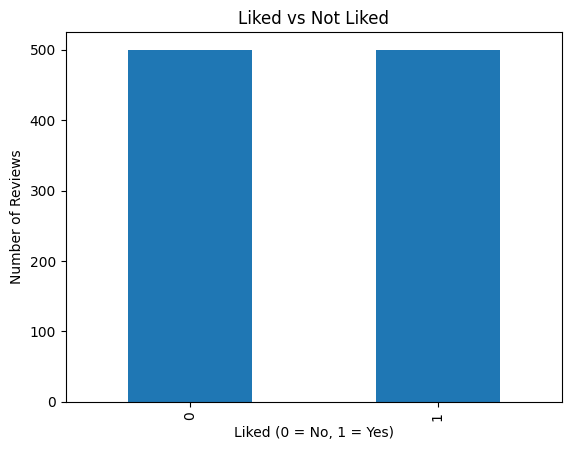

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/Restaurant_Reviews.tsv', sep='\t')

print("Total reviews:", len(df))
print(df['Liked'].value_counts())
print("Liked percentage:", df['Liked'].mean() * 100)

df['Liked'].value_counts().sort_index().plot(kind='bar')
plt.title('Liked vs Not Liked')
plt.xlabel('Liked (0 = No, 1 = Yes)')
plt.ylabel('Number of Reviews')
plt.show()


## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
To do text analysis, we need to remove all of the junk in the reviews.  This would include anything like punctuation, website URLs, emojis, etc.

### Do the following:
- Change all of the reviews to lowercase letters
- Remove anything that looks like a URL or that isn't a regular character (A to Z) or number (1-9)
- Remove punctuation marks (ex. !.,-:;)

In [4]:
df['clean_review'] = (df['Review'].str.lower().str.replace(r'https?://\S+|www\.\S+', '', regex=True).str.replace(r'[^a-z0-9\s]', '', regex=True).str.strip())

display(df[['Review', 'clean_review']].head(10))

,Review,clean_review
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday of...,stopped by during the late may bank holiday of...
4,The selection on the menu was great and so wer...,the selection on the menu was great and so wer...
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it didnt taste that fresh
7,The potatoes were like rubber and you could te...,the potatoes were like rubber and you could te...
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch



### Reflection:
1. What risks might occur if you included the review "junk" in your model?

### ✍️ Your Response: 🔧
1. I think if I included the review "junk" in my model, there'd be a lot of unecessary information which would make it harder to find actual patterns.

## 3. Sentiment Analysis

**Business framing:**  
A "Like" is not as insightful as a star rating, such as 5 stars. It only has two values. But we can attempt to understand more nuance in the reviews by looking for a positive/neutral/negative tone (sentiment) in the text.   Then we can compare that to the "Likes" to see if they match.  

### Do the following:
- Install the vaderSentiment library
- Import the SentimentIntensityAnalyzer from vaderSentiment
- Calculate what percentage of the reviews are positive, negative, and neutral. The total percentages should add up to 100%


In [5]:
!pip -q install vaderSentiment

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

df['score'] = df['Review'].apply(lambda x: analyzer.polarity_scores(x)['compound'])

df['sentiment'] = df['score'].apply(lambda x: 'Positive' if x >= 0.05 else 'Negative' if x <= -0.05 else 'Neutral')

sentiment_pct = df['sentiment'].value_counts(normalize=True) * 100
print(sentiment_pct.round(2))
print("Total:", sentiment_pct.sum())

print("\nLiked percentage:", df['Liked'].mean() * 100)


sentiment
Positive    50.5
Negative    25.0
Neutral     24.5
Name: proportion, dtype: float64
Total: 100.0

Liked percentage: 50.0


### Reflection:
1. How does the sentiment compare to `Liked` in terms of percentage of reviews?
2. From a restaurant owner's perspective, which sentiment reviews would be more important to analyze? (positive, negative or neutral)

### ✍️ Your Response: 🔧
1. In terms of percentage of reviews, the dataset was 50 like and 50 dislike, but VADER showed it as 50.5% positive, 25% negative, and 24.5% negative. So it separated the neutral and negative and for positive, there was a 0.5 percent difference.

2. Honestly, I think that from a restaurant owner's perspective that negative reviews would be more important to analyze just so we can figure out why and what is the root of the problem to help make the business more sucessful.

## 4. Topic Analysis - Text Preprocessing

**Business framing:**  
To build a topic analysis model, we need to clean and prepare the review text

### Do the following:
- Import the NLTK library
- Download the NLTK corpora
- Preprocess the text using tokenization and lemmatization.  Be sure to remove any stopwords along the way.
- Display the first 10 processed reviews

In [6]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    words = word_tokenize(text)
    return [lemmatizer.lemmatize(w) for w in words
            if w.isalnum() and w not in stop_words]

df['tokens'] = df['clean_review'].apply(preprocess)
display(df[['Review', 'tokens']].head(10))


,Review,tokens
0,Wow... Loved this place.,"[wow, loved, place]"
1,Crust is not good.,"[crust, good]"
2,Not tasty and the texture was just nasty.,"[tasty, texture, nasty]"
3,Stopped by during the late May bank holiday of...,"[stopped, late, may, bank, holiday, rick, stev..."
4,The selection on the menu was great and so wer...,"[selection, menu, great, price]"
5,Now I am getting angry and I want my damn pho.,"[getting, angry, want, damn, pho]"
6,Honeslty it didn't taste THAT fresh.),"[honeslty, didnt, taste, fresh]"
7,The potatoes were like rubber and you could te...,"[potato, like, rubber, could, tell, made, ahea..."
8,The fries were great too.,"[fry, great]"
9,A great touch.,"[great, touch]"


### Reflection:
1. What is a corpora and how is it used for text analysis?
2. What would be the tokens in the first review? "Wow... Loved this place."
3. What does lemmatization do?  How will it help in this process?

### ✍️ Your Response: 🔧
1. A Corpora is basically a large collection of texts used for analyzing language data. It's used for text analysis by finding patterns and meaning in words and sums up a topic through customer reviews.

2. After processing the text by removing any puncuation and making it lowercase, etc, it would be ['wow, 'loved, 'place].

3. Lemmatization basially groups words that are similar to each other (based on grammar) instead of keeping everything separate. This will help in the process because it reduces variation for anything that is uncessary.

## 5. Topic Analysis - Dictionary and Corpus

**Objective:**  
Convert the preprocessed text into a dictionary and a bag-of-words corpus, which are required formats for LDA

### Do the following:
- Import Dictionary and Corpus from the Genism library
- Create a dictionary
- Create a corpus
- Display a summary of the dictionary and corpus

In [8]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 30.3 MB/s  0:00:00


In [9]:
from gensim.corpora import Dictionary

dictionary = Dictionary(df['tokens'])
corpus = [dictionary.doc2bow(tokens) for tokens in df['tokens']]

print("Unique words:", len(dictionary))
print("Documents:", len(corpus))
print("First document:", corpus[0])

Unique words: 1839
Documents: 1000
First document: [(0, 1), (1, 1), (2, 1)]


### Reflection:
1. What is a corpus and how is it useful?
2. How is a dictionary different from a corpus?

### ✍️ Your Response: 🔧
1. A corpus is a large set of texts that is usually electronically stored and it is to be used for text analysis. It is useful because it helps reserachers stude how the language is used in real life. For example, for the restaurant reviews, it helps us interpret the data and find patterns.

2. A dictionary is different from a corpus because a dictionary assigns a Unique ID to every single word in the dataset. On the other hand, a corpus shows the frequency of how often the word shows up in every review.

## 6. Topic Analysis - Build LDA Model

**Objective:**  
Apply the LDA model to the corpus to identify main topics.

### Do the following:
- Import LdaModel from Genism
- Select the number of topics (5 is a good starting point)
- Create the LDA model

NOTE: You may receive an error about training "not converging".  You can ignore that error for this assignment. (Let's keep it simple)


In [10]:
from gensim.models import LdaModel

lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=5, random_state=42, passes=20)

for topic_id, words in lda.print_topics(num_words=10):
    print(f"Topic {topic_id + 1}: {words}\n")


Topic 1: 0.024*"good" + 0.020*"place" + 0.019*"food" + 0.016*"dont" + 0.010*"would" + 0.010*"time" + 0.010*"go" + 0.009*"best" + 0.009*"star" + 0.007*"really"

Topic 2: 0.016*"good" + 0.015*"place" + 0.014*"also" + 0.013*"time" + 0.012*"friendly" + 0.009*"ive" + 0.007*"waited" + 0.007*"go" + 0.007*"back" + 0.006*"pizza"

Topic 3: 0.015*"place" + 0.011*"minute" + 0.011*"amazing" + 0.011*"food" + 0.010*"great" + 0.009*"like" + 0.007*"taste" + 0.007*"pretty" + 0.006*"ordered" + 0.006*"flavor"

Topic 4: 0.034*"food" + 0.024*"back" + 0.014*"like" + 0.013*"ever" + 0.012*"wont" + 0.011*"service" + 0.008*"one" + 0.008*"go" + 0.008*"best" + 0.007*"even"

Topic 5: 0.039*"service" + 0.026*"great" + 0.023*"place" + 0.016*"food" + 0.016*"good" + 0.009*"restaurant" + 0.009*"time" + 0.008*"delicious" + 0.007*"well" + 0.007*"definitely"



### Reflection:
1. In what cases would you want to use more than 5 topics?  
2. How would you know if you have too many topics?

### ✍️ Your Response: 🔧
1. I would want to use more than 5 topics if there were more insight from customers that wouldn't fit into any of these.

2. I would know if I have too many topics if they start to sound the same or could be grouped/narrowed down even more.

## 7. Summarize the Topics

**Business framing:**  
Now comes one of the most challenging steps.  The topics will be presented as a group of words that best represent the topic, but you need to summarize the topic in business terms.   

### Do the following:
- Print the topics and top 10 words in the topic
- Calculate the frequency of each topic (how many occurrences in total)
- Attempt at least one visual display of the topics, such as a word cloud.  (Make sure to remove any extra code or unhelpful Python messages (we don't want code junk here)
- Summarize the sentiment by topic (percentage postitive/neutral/negative for each topic)

Topic 1: [('good', np.float32(0.024079971)), ('place', np.float32(0.019673439)), ('food', np.float32(0.019091137)), ('dont', np.float32(0.015629804)), ('would', np.float32(0.010330588)), ('time', np.float32(0.010155837)), ('go', np.float32(0.00982084)), ('best', np.float32(0.00920193)), ('star', np.float32(0.008881299)), ('really', np.float32(0.0072824317))]
Topic 2: [('good', np.float32(0.016165782)), ('place', np.float32(0.015180614)), ('also', np.float32(0.014384578)), ('time', np.float32(0.012531048)), ('friendly', np.float32(0.012426062)), ('ive', np.float32(0.009030223)), ('waited', np.float32(0.006758065)), ('go', np.float32(0.006568693)), ('back', np.float32(0.0065368046)), ('pizza', np.float32(0.0063250186))]
Topic 3: [('place', np.float32(0.015407499)), ('minute', np.float32(0.010959842)), ('amazing', np.float32(0.010660346)), ('food', np.float32(0.010622422)), ('great', np.float32(0.009951247)), ('like', np.float32(0.009351976)), ('taste', np.float32(0.007439775)), ('pretty'

sentiment,Negative,Neutral,Positive
topic,,,
1,21.36,31.55,47.09
2,24.54,24.54,50.92
3,27.68,22.03,50.28
4,28.85,28.37,42.79
5,23.17,17.07,59.76


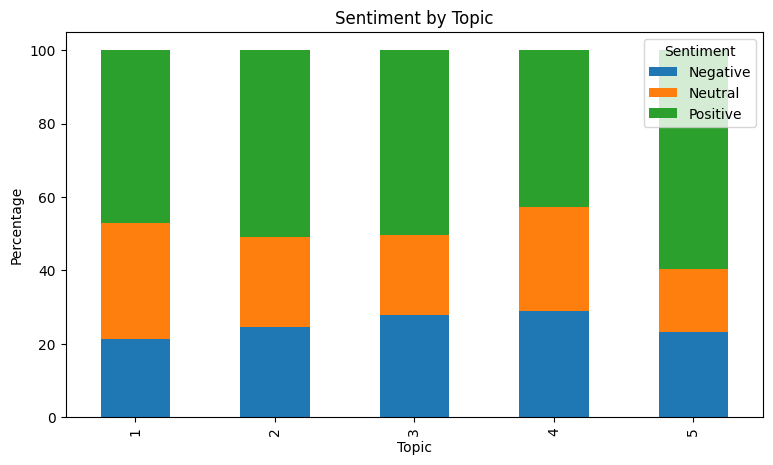

In [11]:
from wordcloud import WordCloud

# Show top 10 words for each topic
for i in range(5):
    print(f"Topic {i+1}:", lda.show_topic(i, topn=10))

# Assign each review its most likely topic
df['topic'] = [max(lda.get_document_topics(doc), key=lambda x: x[1])[0] + 1 for doc in corpus]

print("\nTopic frequencies:")
print(df['topic'].value_counts().sort_index())

# Word cloud
words = ' '.join(df['tokens'].apply(lambda x: ' '.join(x)))
WordCloud(width=800, height=400, background_color='white').generate(words).to_image()

# Sentiment percentage for each topic
topic_sentiment = pd.crosstab(df['topic'], df['sentiment'], normalize='index') * 100

display(topic_sentiment.round(2))

topic_sentiment.plot(kind='bar', stacked=True, figsize=(9, 5))
plt.title('Sentiment by Topic')
plt.xlabel('Topic')
plt.ylabel('Percentage')
plt.legend(title='Sentiment')
plt.show()


### Reflection:
1. Give each topic a 2-3 word name.  You should list the topic number and a name that you will create that summarize the words used.  For example, "Topic #1 - Slow Service"

### ✍️ Your Response: 🔧
List your topics and names here:
Topic #1 - "Food Quality"
Topic #2 - "Dining Experience"
Topic #3 - "Food and Service"
Topic #4 - "Restaurant Experience"
Topic #5 - "Service Quality"

## 8. Reflect and Recommend

**Business framing:**  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to this restaurant to improve customer satisfaction?
3. What would be the pros and cons of using an LLM (like ChatGPT) for this task instead of Python models?
4. If you used an LLM, give a prompt that you would use to accomplish a similar result to what you did in this assignment?  (remember to set the context, specify the output and explain the objectives)


### ✍️ Your Response: 🔧
1. My model helped answer how customers feel about the restaurant and what kind of experiences they've had.

2. To improve customer satisfaction, I would recommend this restaurant to focus on improving their food quality and customer experience because those were the most frequent in the reviews.

3. The pro about using an LLM like ChatGPT insitead of Python models is that it can summarize reviews for you quickly. The con is that it's not as accurate and doesn't have as much control as Python does. Python uses coding and models so you can actually see what is happening.

4. Pretend that you are a data analyst for a restaurant. Analyze this dataset I've attached, it has 1,000 customer reviews. Find the most common topics discussed, and group them into categories of positive, negative, and neutral, and then after that, come up with five major topics. Make sure to include the topic frequencies and percentages. After that, come up with ways on how you can improve the restaurant to make your customer reviews more positive.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_13_text_analytics.ipynb"